# Trajectory: how the out-of-distribution score grows with the training set

Two-stage ensembles trained on 20–80% of the configs below the pressure cut, each scored on a fixed 20% below the cut (in range) and on the public configs above it (out of distribution).

In [1]:
import os
from pathlib import Path

if Path.cwd().name == "notebooks":
    os.chdir("..")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import pallas_pipeline as pp
import pallas_score

project = pp.connect(pp.PROJECT)
fs = project.get_feature_store()
case = pp.CASES["trajectory"]
PARAMS = {"two_stage": True, "use_physics": True, "physics": ["dE_gain", "n_e"], "val_fraction": 1 / 3, "device": "cuda:1"}
seed = 12
out = Path("team_models/ood_budget_two_stage")
out.mkdir(parents=True, exist_ok=True)

/home/mlenivenko/miniconda3/envs/torch/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


2026-10-15 16:52:25,263 INFO: Initializing external client


2026-10-15 16:52:25,264 INFO: Base URL: https://aissai26.hops.live:443


2026-10-15 16:52:26,639 INFO: Python Engine initialized.



Logged in to project, explore it here https://aissai26.hops.live:443/p/2170


In [2]:
fv = pp.get_feature_view(fs, "m_trajectory_raw_fv", 1)
rows = pp.read_rows(fv, case)
inside = set(pp.pack_reference()["sections"]["ood_split"]["train"])
below = np.array(sorted(c for c in rows.config.unique() if c in inside))
above = sorted(c for c in rows.config.unique() if c not in inside)
shuffled = np.random.default_rng(seed).permutation(below)
n_test = round(0.2 * len(below))
budgets = {b: shuffled[n_test:][:round(b * len(below))] for b in [0.2, 0.4, 0.6, 0.8]}


def test_set(configs):
    part = rows[rows.config.isin(configs)].reset_index(drop=True)
    return {"rows": part, "X": pp.transform(fv, part, case), "key": pp.answer_key(case, part),
            "true": np.column_stack([pallas_score.physical_to_normalised(t, part[t]) for t in case.targets]),
            "inside": (part.z_mm <= part.L_inj + pallas_score.PLASMA_END_OFFSET_MM).to_numpy()}


tests = {"in range": test_set(shuffled[:n_test]), "out of distribution": test_set(above)}
columns = list(tests["in range"]["X"].columns)
print({b: len(c) for b, c in budgets.items()}, {k: t["rows"].config.nunique() for k, t in tests.items()})

Finished: Reading data from Hopsworks, using Hopsworks Feature Query Service (1.25s) 
{0.2: 455, 0.4: 911, 0.6: 1366, 0.8: 1822} {'in range': 455, 'out of distribution': 578}


## Train and score

In [3]:
results = []
for b, configs in budgets.items():
    train = rows[rows.config.isin(configs)].reset_index(drop=True)
    for f in ["mlp_deep_ensemble", "film_deep_ensemble"]:
        module = pp.load_model_file(f"models/{f}.py")
        model = pp.SurrogateModel(module.build_model(**{**module.PARAMS, **PARAMS, "columns": columns}), case.targets, "scorer")
        model.fit(pp.transform(fv, train, case)[columns], train)
        row = {"model": f, "budget": b, "train configs": len(configs)}
        for name, t in tests.items():
            scores = pallas_score.score_submission(pp.predictions(case, model, t["X"][columns], t["rows"]), t["key"])
            mean, spread = model.estimator.predict_with_spread(np.asarray(t["X"][columns], float))
            row[name] = scores["mean"]
            row.update({f"{name} {tg}": scores[tg] for tg in case.targets})
            row.update({f"{name} cover2 {tg}": c for tg, c in zip(case.targets, (np.abs(t["true"] - mean) < 2 * spread)[t["inside"]].mean(0))})
        row["gap"] = row["in range"] - row["out of distribution"]
        results.append(row)
        print(f"{f}, {int(b * 100)}%: in range {row['in range']:.4f}, out of distribution {row['out of distribution']:.4f}")
table = pd.DataFrame(results)
table.to_csv(out / "results.csv", index=False)
table.pivot(index="budget", columns="model", values=["in range", "out of distribution", "gap"]).round(4)

303 train / 152 validation configurations, 5 + 3 inputs, on cuda:1


member 0: epoch 131


member 1: epoch 178


member 2: epoch 167


member 3: epoch 170


...

member 2: epoch 149


member 3: epoch 169


member 4: epoch 177


film_deep_ensemble, 80%: in range 0.9878, out of distribution 0.9613


in range                   out of distribution  \
model  film_deep_ensemble mlp_deep_ensemble  film_deep_ensemble   
budget                                                            
0.2                0.9735            0.9699              0.8719   
0.4                0.9834            0.9818              0.9414   
0.6                0.9859            0.9852              0.9554   
0.8                0.9878            0.9866              0.9613   

                                        gap                    
model  mlp_deep_ensemble film_deep_ensemble mlp_deep_ensemble  
budget                                                         
0.2               0.8915             0.1015            0.0784  
0.4               0.9421             0.0420            0.0397  
0.6               0.9550             0.0305            0.0302  
0.8               0.9623             0.0265            0.0242

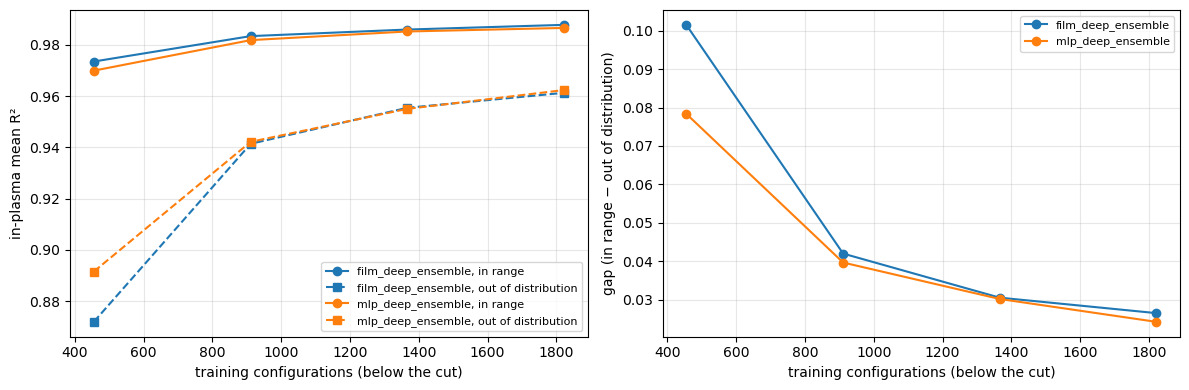

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for (f, part), color in zip(table.groupby("model"), ["C0", "C1"]):
    axes[0].plot(part["train configs"], part["in range"], "o-", color=color, label=f"{f}, in range")
    axes[0].plot(part["train configs"], part["out of distribution"], "s--", color=color, label=f"{f}, out of distribution")
    axes[1].plot(part["train configs"], part["gap"], "o-", color=color, label=f)
axes[0].set_ylabel("in-plasma mean R²")
axes[1].set_ylabel("gap (in range − out of distribution)")
for ax in axes:
    ax.set_xlabel("training configurations (below the cut)")
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(out / "budget_curves.png", dpi=130)

In [5]:
per_target = table.melt(id_vars=["model", "budget"], value_vars=[f"{s} {t}" for s in tests for t in case.targets])
per_target["test"] = per_target.variable.str.rsplit(" ", n=1).str[0]
per_target["target"] = per_target.variable.str.rsplit(" ", n=1).str[1]
per_target.pivot_table(index=["test", "target"], columns=["model", "budget"], values="value").round(3)

model                        film_deep_ensemble                       \
budget                                      0.2    0.4    0.6    0.8   
test                target                                             
in range            E_MeV                 0.995  0.997  0.998  0.998   
                    dE_pct                0.961  0.980  0.983  0.984   
                    div_mrad              0.975  0.983  0.984  0.986   
                    emit_um               0.970  0.978  0.980  0.980   
                    q_pC                  0.994  0.998  0.999  0.999   
                    sigz_um               0.945  0.965  0.972  0.979   
out of distribution E_MeV                 0.976  0.984  0.987  0.990   
                    dE_pct                0.919  0.948  0.967  0.973   
                    div_mrad              0.955  0.969  0.971  0.974   
                    emit_um               0.855  0.944  0.955  0.957   
                    q_pC                  0.991  0.997  0.998  0.998   
                    sigz_um               0.535  0.806  0.855  0.875   

model                        mlp_deep_ensemble                       
budget                                     0.2    0.4    0.6    0.8  
test                target                                           
in range            E_MeV                0.995  0.997  0.998  0.998  
                    dE_pct               0.958  0.977  0.982  0.983  
                    div_mrad             0.976  0.982  0.983  0.985  
                    emit_um              0.964  0.976  0.978  0.979  
                    q_pC                 0.994  0.998  0.998  0.999  
                    sigz_um              0.932  0.962  0.971  0.976  
out of distribution E_MeV                0.978  0.984  0.988  0.988  
                    dE_pct               0.924  0.945  0.964  0.972  
                    div_mrad             0.961  0.969  0.974  0.979  
                    emit_um              0.913  0.949  0.955  0.964  
                    q_pC                 0.995  0.997  0.997  0.998  
                    sigz_um              0.580  0.809  0.851  0.873